## Import library

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import joblib


## Load dataset

In [14]:
df = pd.read_csv('cleaned_hourly_demand.csv')
df['order_timestamp'] = pd.to_datetime(df['order_timestamp'])
df = df.sort_values(by=['restaurant_id', 'order_timestamp'])

## Feature Enginnering



In [15]:
# Membantu model non-time-series memahami urutan waktu
df['demand_lag_1'] = df.groupby('restaurant_id')['demand'].shift(1)
df['demand_lag_2'] = df.groupby('restaurant_id')['demand'].shift(2)
df['demand_lag_24'] = df.groupby('restaurant_id')['demand'].shift(24)
df['demand_lag_24'] = df.groupby('restaurant_id')['demand'].shift(24)
df['total_items_lag_1'] = df.groupby('restaurant_id')['total_items'].shift(1)
df['total_items_lag_24'] = df.groupby('restaurant_id')['total_items'].shift(24)
# Tambahkan ini di bagian Feature Engineering sebelum di-split

# Rata-rata order dalam 3 jam terakhir SEBELUM jam ini
df['rolling_mean_3h'] = df.groupby('restaurant_id')['demand'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
)

# Rata-rata order dalam 6 jam terakhir SEBELUM jam ini
df['rolling_mean_6h'] = df.groupby('restaurant_id')['demand'].transform(
    lambda x: x.shift(1).rolling(window=6, min_periods=1).mean()
)

# Standar deviasi order 3 jam terakhir SEBELUM jam ini
df['rolling_std_3h'] = df.groupby('restaurant_id')['demand'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).std().fillna(0)
)

df = df.dropna().reset_index(drop=True)

# Definisikan fitur dan target
target = 'demand'
num_features = ['demand_lag_1', 'demand_lag_2', 'demand_lag_24', 'total_items_lag_1',"total_items_lag_24",'rolling_mean_3h','rolling_mean_6h','rolling_std_3h']
cat_features = ['order_hour', 'day_of_week', 'is_weekend', 'weather', 'traffic_level']

X = df[num_features + cat_features]
y = df[target]

# List untuk menampung data train dan test yang bersih
X_train_list, X_test_list = [], []
y_train_list, y_test_list = [], []

# Split 80/20 dilakukan per restoran agar urutan waktu tidak rusak
for rest_id, group in df.groupby('restaurant_id'):
    split_idx = int(len(group) * 0.8)

    # Pisahkan fitur dan target untuk grup restoran ini
    X_group = group[num_features + cat_features]
    y_group = group[target]

    # Masukkan ke list masing-masing
    X_train_list.append(X_group.iloc[:split_idx])
    X_test_list.append(X_group.iloc[split_idx:])
    y_train_list.append(y_group.iloc[:split_idx])
    y_test_list.append(y_group.iloc[split_idx:])

# Gabungkan kembali semua data restoran
X_train = pd.concat(X_train_list).reset_index(drop=True)
X_test = pd.concat(X_test_list).reset_index(drop=True)
y_train = pd.concat(y_train_list).reset_index(drop=True)
y_test = pd.concat(y_test_list).reset_index(drop=True)

print(f"Shape X_train: {X_train.shape}, Shape y_train: {y_train.shape}")
print(f"Shape X_test: {X_test.shape}, Shape y_test: {y_test.shape}")


Shape X_train: (3938, 13), Shape y_train: (3938,)
Shape X_test: (989, 13), Shape y_test: (989,)


In [16]:
df

,restaurant_id,order_timestamp,demand,service_process_mean,order_hour,day_of_week,is_weekend,weather,traffic_level,total_items,avg_subtotal,demand_lag_1,demand_lag_2,demand_lag_24,total_items_lag_1,total_items_lag_24,rolling_mean_3h,rolling_mean_6h,rolling_std_3h
0,RES_0001,2025-10-02 00:00:00,3,16.000000,0,Thursday,0,Rain,Low,6,18.580000,8.0,6.0,6.0,25.0,18.0,6.666667,15.000000,1.154701
1,RES_0001,2025-10-02 01:00:00,3,14.333333,1,Thursday,0,Rain,Low,11,31.686667,3.0,8.0,3.0,6.0,9.0,5.666667,12.166667,2.516611
2,RES_0001,2025-10-02 02:00:00,4,14.250000,2,Thursday,0,Rain,Low,10,20.125000,3.0,3.0,1.0,11.0,6.0,4.666667,9.833333,2.886751
3,RES_0001,2025-10-02 03:00:00,5,13.200000,3,Thursday,0,Rain,Low,14,28.194000,4.0,3.0,1.0,10.0,1.0,3.333333,5.000000,0.577350
4,RES_0001,2025-10-02 04:00:00,4,17.500000,4,Thursday,0,Rain,Low,17,38.067500,5.0,4.0,2.0,14.0,4.0,4.000000,4.833333,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4922,RES_0010,2025-10-30 18:00:00,1,5.000000,18,Thursday,0,Cloudy,Low,1,10.090000,1.0,2.0,1.0,1.0,4.0,2.000000,1.833333,1.000000
4923,RES_0010,2025-10-30 19:00:00,9,15.111111,19,Thursday,0,Cloudy,Medium,27,26.541111,1.0,1.0,2.0,1.0,9.0,1.333333,1.833333,0.577350
4924,RES_0010,2025-10-30 20:00:00,1,22.000000,20,Thursday,0,Cloudy,Medium,4,37.620000,9.0,1.0,1.0,27.0,3.0,3.666667,3.000000,4.618802
4925,RES_0010,2025-10-30 21:00:00,2,14.000000,21,Thursday,0,Cloudy,Medium,3,12.930000,1.0,9.0,1.0,4.0,1.0,3.666667,2.833333,4.618802


In [17]:
df.to_csv('cleaned_hourly_demand_final.csv', index=False)

## BUILD PREPROCESSING PIPELINE

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
    ])

## TRAIN & EVALUATE TRADITIONAL MODELS

In [19]:
model =XGBRegressor(
    objective='count:poisson',
    eval_metric='poisson-nloglik',
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42
)


In [20]:
evaluation_results = {}

In [21]:
print("Training Models...")

pipeline = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])

# Train
pipeline.fit(X_train, y_train)

# Predict
y_pred = pipeline.predict(X_test)

# Evaluate
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

evaluation_results['XGBRegressor'] = {'MAE': mae, 'MSE': mse, 'R2': r2}
print("✅ XGBRegressor trained.")


Training Models...
✅ XGBRegressor trained.


In [22]:
results_df = pd.DataFrame(evaluation_results).T
print("\n=== EVALUATION RESULTS FOR MODEL FORECASTING ===")
results_df.sort_values(by='MAE')


=== EVALUATION RESULTS FOR MODEL FORECASTING ===


,MAE,MSE,R2
XGBRegressor,1.878704,7.34099,0.771186


In [23]:
save_path = 'model_demand_pipeline.pkl'
joblib.dump(pipeline, save_path)
print(f"\n🏆 Model  saved with MAE: {mae:.4f}")


🏆 Model  saved with MAE: 1.8787


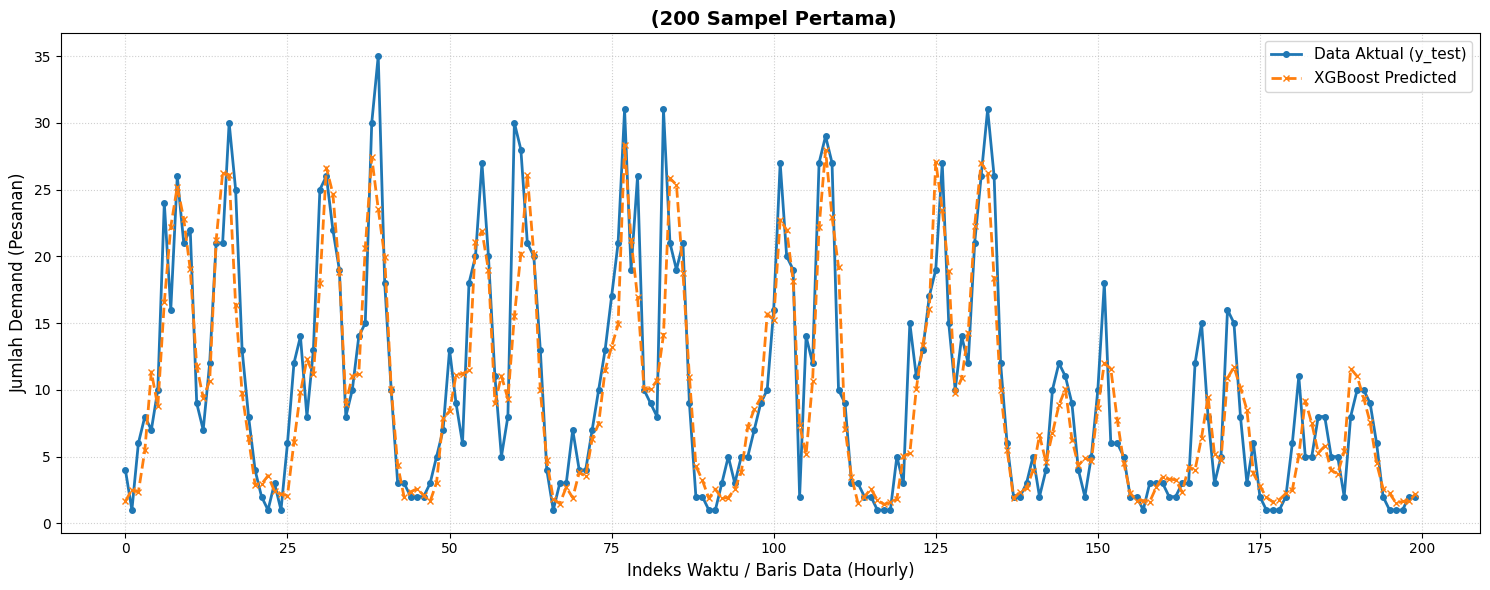

In [24]:
import matplotlib.pyplot as plt
import numpy as np

n_samples = 200

y_test_array = np.array(y_test)[:n_samples]

# Membuat plot grafik
plt.figure(figsize=(15, 6))

plt.plot(y_test_array, label='Data Aktual (y_test)', color='#1f77b4', linewidth=2, marker='o', markersize=4)

plt.plot(pipeline.predict(X_test)[:n_samples], label='XGBoost Predicted', color='#ff7f0e', linewidth=2, linestyle='--', marker='x', markersize=4)

plt.title(f' ({n_samples} Sampel Pertama)', fontsize=14, fontweight='bold')
plt.xlabel('Indeks Waktu / Baris Data (Hourly)', fontsize=12)
plt.ylabel('Jumlah Demand (Pesanan)', fontsize=12)
plt.legend(fontsize=11, loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

# Menampilkan grafik di Colab
plt.tight_layout()
plt.show()
